## Definición del problema

El objetivo principal del proyecto es maximizar la rentabilidad de la cartera de créditos mediante la reducción de las pérdidas asociadas al incumplimiento de pago, procurando mantener un volumen de colocaciones que favorezca el crecimiento del negocio.

Desde la perspectiva de Machine Learning, el problema se aborda mediante el desarrollo de un modelo predictivo de clasificación, cuyo propósito es identificar a los clientes con riesgo de incumplimiento de sus obligaciones financieras. Estas predicciones obtenidas servirán como herramienta de apoyo para la evaluación crediticia y la toma de decisiones relacionadas con la gestión de la cartera.

Para el desarrollo del modelo se utilizará el conjunto de datos **Give Me Some Credit**, que contiene información financiera y características del comportamiento crediticio de los clientes.

| Nombre de la variable | Descripción |
|---|---|
| SeriousDlqin2yrs | Indica si la persona experimentó una morosidad grave de 90 días o más durante los últimos 2 años. |
| RevolvingUtilizationOfUnsecuredLines | Saldo total utilizado en tarjetas de crédito y líneas de crédito personales (excluyendo préstamos hipotecarios y otras deudas a plazos, como préstamos vehiculares), dividido entre la suma de sus límites de crédito. |
| age | Edad del prestatario en años. |
| NumberOfTime30-59DaysPastDueNotWorse | Número de veces que el prestatario presentó entre 30 y 59 días de atraso en sus pagos, sin alcanzar una situación de morosidad más grave, durante los últimos 2 años. |
| DebtRatio | Relación entre los pagos mensuales de deudas, pensiones alimenticias y gastos de manutención, respecto a los ingresos brutos mensuales. |
| MonthlyIncome | Ingresos mensuales del prestatario. |
| NumberOfOpenCreditLinesAndLoans | Número de préstamos vigentes (como préstamos vehiculares o hipotecarios) y líneas de crédito abiertas (por ejemplo, tarjetas de crédito). |
| NumberOfTimes90DaysLate | Número de veces que el prestatario presentó un atraso de 90 días o más en sus pagos. |
| NumberRealEstateLoansOrLines | Número de préstamos hipotecarios y créditos inmobiliarios, incluidas las líneas de crédito con garantía hipotecaria. |
| NumberOfTime60-89DaysPastDueNotWorse | Número de veces que el prestatario presentó entre 60 y 89 días de atraso en sus pagos, sin alcanzar una situación de morosidad más grave, durante los últimos 2 años. |
| NumberOfDependents | Número de personas dependientes económicamente del prestatario, excluyéndolo a él mismo (cónyuge, hijos, etc.). |

## Análisis exploratorio y preprocesamiento de datos

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import lightgbm as lgb
import xgboost as xgb
import shap

from sklearn.impute import KNNImputer
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score, roc_curve, classification_report
from scipy.stats import ks_2samp

In [2]:
df = pd.read_csv('/content/cs-training.csv', index_col=0)

In [3]:
df.head()

,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
1,1,0.766127,45,2,0.802982,9120.0,13,0,6,0,2.0
2,0,0.957151,40,0,0.121876,2600.0,4,0,0,0,1.0
3,0,0.658180,38,1,0.085113,3042.0,2,1,0,0,0.0
4,0,0.233810,30,0,0.036050,3300.0,5,0,0,0,0.0
5,0,0.907239,49,1,0.024926,63588.0,7,0,1,0,0.0


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 150000 entries, 1 to 150000
Data columns (total 11 columns):
 #   Column                                Non-Null Count   Dtype  
---  ------                                --------------   -----  
 0   SeriousDlqin2yrs                      150000 non-null  int64  
 1   RevolvingUtilizationOfUnsecuredLines  150000 non-null  float64
 2   age                                   150000 non-null  int64  
 3   NumberOfTime30-59DaysPastDueNotWorse  150000 non-null  int64  
 4   DebtRatio                             150000 non-null  float64
 5   MonthlyIncome                         120269 non-null  float64
 6   NumberOfOpenCreditLinesAndLoans       150000 non-null  int64  
 7   NumberOfTimes90DaysLate               150000 non-null  int64  
 8   NumberRealEstateLoansOrLines          150000 non-null  int64  
 9   NumberOfTime60-89DaysPastDueNotWorse  150000 non-null  int64  
 10  NumberOfDependents                    146076 non-null  float64
dtypes: fl

El conjunto de datos está compuesto por 150,000 registros y 11 variables: 10 predictoras y una variable objetivo (SeriousDlqin2yrs). Primero, se verifica la presencia de valores faltantes.

In [5]:
datos_faltantes = df.isnull().mean() * 100
print(datos_faltantes[datos_faltantes > 0])

MonthlyIncome         19.820667
NumberOfDependents     2.616000
dtype: float64


La variable MonthlyIncome presenta aproximadamente un 20% de valores faltantes. Esta ausencia podría estar relacionada con la falta de información sobre los ingresos de determinados clientes, aunque no es posible establecer su causa con certeza. Por otro lado, vemos que la columna NumberOfDepends tiene casi un 3% de valores faltantes. Primero, evaluamos la escala de las variables antes de decidir la estrategia de imputación.

In [6]:
columnas_imputar = ['MonthlyIncome', 'NumberOfDependents']

display(df[columnas_imputar].describe().T)

,count,mean,std,min,25%,50%,75%,max
MonthlyIncome,120269.0,6670.221237,14384.674215,0.0,3400.0,5400.0,8249.0,3008750.0
NumberOfDependents,146076.0,0.757222,1.115086,0.0,0.0,0.0,1.0,20.0


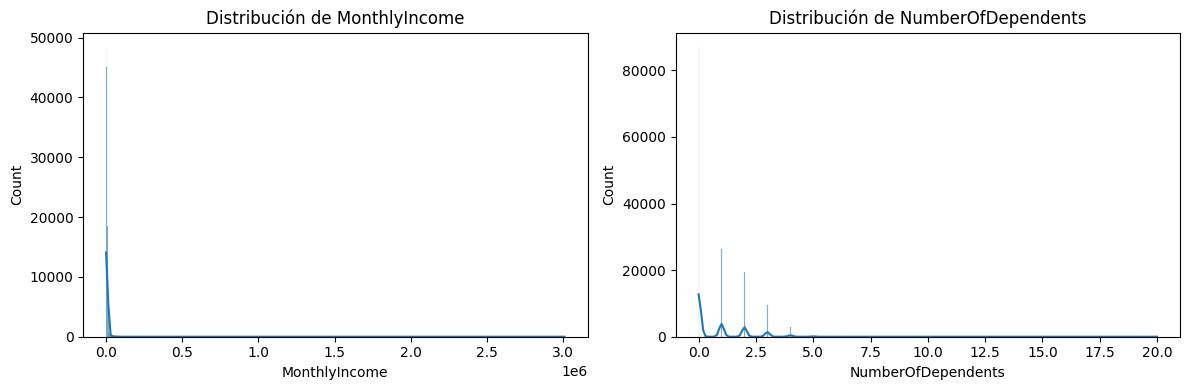

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, col in zip(axes, columnas_imputar):
    sns.histplot(df[col].dropna(), kde=True, ax=ax)
    ax.set_title(f'Distribución de {col}')
    ax.set_xlabel(col)

plt.tight_layout()
plt.show()

En relación con la variable MonthlyIncome, se aprecia que la media es superior a la mediana y el valor máximo es considerablemente elevado respecto al resto de observaciones. Esto evidencia una distribución asimétrica positiva y la posible presencia de valores atípicos.
Con respecto a la variable NumberOfDependents, se evidencia que está concentrada principalmente en valores pequeños, especialmente 0 y 1. Para un mejor análisis, vamos a cuantificar la asimetría y detectar posibles valores atípicos mediante el rango intercuartílico (IQR).

In [8]:
for col in columnas_imputar:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    limite_inferior = Q1 - 1.5 * IQR
    limite_superior = Q3 + 1.5 * IQR

    print(f'\n{col}')
    print(f'Asimetría: {df[col].skew():.2f}')
    print(f'Límite inferior: {limite_inferior:.2f}')
    print(f'Límite superior: {limite_superior:.2f}')
    print(f'Posibles valores atípicos: '
          f'{((df[col] < limite_inferior) | (df[col] > limite_superior)).sum()}')


MonthlyIncome
Asimetría: 114.04
Límite inferior: -3873.50
Límite superior: 15522.50
Posibles valores atípicos: 4879

NumberOfDependents
Asimetría: 1.59
Límite inferior: -1.50
Límite superior: 2.50
Posibles valores atípicos: 13336


Se identificó una elevada asimetría en la variable MonthlyIncome y una concentración de valores pequeños en NumberOfDependents. Debido a estas características, se optó por utilizar la mediana como método de imputación, ya que es menos sensible a los valores extremos que la media. Adicionalmente, se conservaron indicadores binarios para identificar los registros que originalmente presentaban valores faltantes.

In [9]:
df['MonthlyIncomeIsNull'] = df['MonthlyIncome'].isnull().astype(int)
df['NumberOfDependentsIsNull'] = df['NumberOfDependents'].isnull().astype(int)

columnas_imputar = ['MonthlyIncome', 'NumberOfDependents']

for col in columnas_imputar:
    df[col] = df[col].fillna(df[col].median())

print(df[columnas_imputar].isnull().sum())

MonthlyIncome         0
NumberOfDependents    0
dtype: int64


Se analiza la distribución de la variable objetivo SeriousDlqin2yrs para identificar posibles problemas de desbalance de clases.

In [10]:
df['SeriousDlqin2yrs'].value_counts(normalize=True) * 100

,proportion
SeriousDlqin2yrs,
0,93.316
1,6.684


Los resultados muestran que el 93.32% de las observaciones pertenece a la clase 0 (clientes sin incumplimiento grave), mientras que el 6.68% corresponde a la clase 1 (clientes con incumplimiento grave). Esta distribución evidencia un desbalance significativo, por lo que será necesario considerarlo durante el desarrollo y la evaluación de los modelos predictivos.
A continuación, se procede a identificar la presencia de valores atípicos en el conjunto de datos.

In [11]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
SeriousDlqin2yrs,150000.0,0.066840,0.249746,0.0,0.000000,0.000000,0.000000,1.0
RevolvingUtilizationOfUnsecuredLines,150000.0,6.048438,249.755371,0.0,0.029867,0.154181,0.559046,50708.0
age,150000.0,52.295207,14.771866,0.0,41.000000,52.000000,63.000000,109.0
NumberOfTime30-59DaysPastDueNotWorse,150000.0,0.421033,4.192781,0.0,0.000000,0.000000,0.000000,98.0
DebtRatio,150000.0,353.005076,2037.818523,0.0,0.175074,0.366508,0.868254,329664.0
MonthlyIncome,150000.0,6418.454920,12890.395542,0.0,3903.000000,5400.000000,7400.000000,3008750.0
NumberOfOpenCreditLinesAndLoans,150000.0,8.452760,5.145951,0.0,5.000000,8.000000,11.000000,58.0
NumberOfTimes90DaysLate,150000.0,0.265973,4.169304,0.0,0.000000,0.000000,0.000000,98.0
NumberRealEstateLoansOrLines,150000.0,1.018240,1.129771,0.0,0.000000,1.000000,2.000000,54.0
NumberOfTime60-89DaysPastDueNotWorse,150000.0,0.240387,4.155179,0.0,0.000000,0.000000,0.000000,98.0


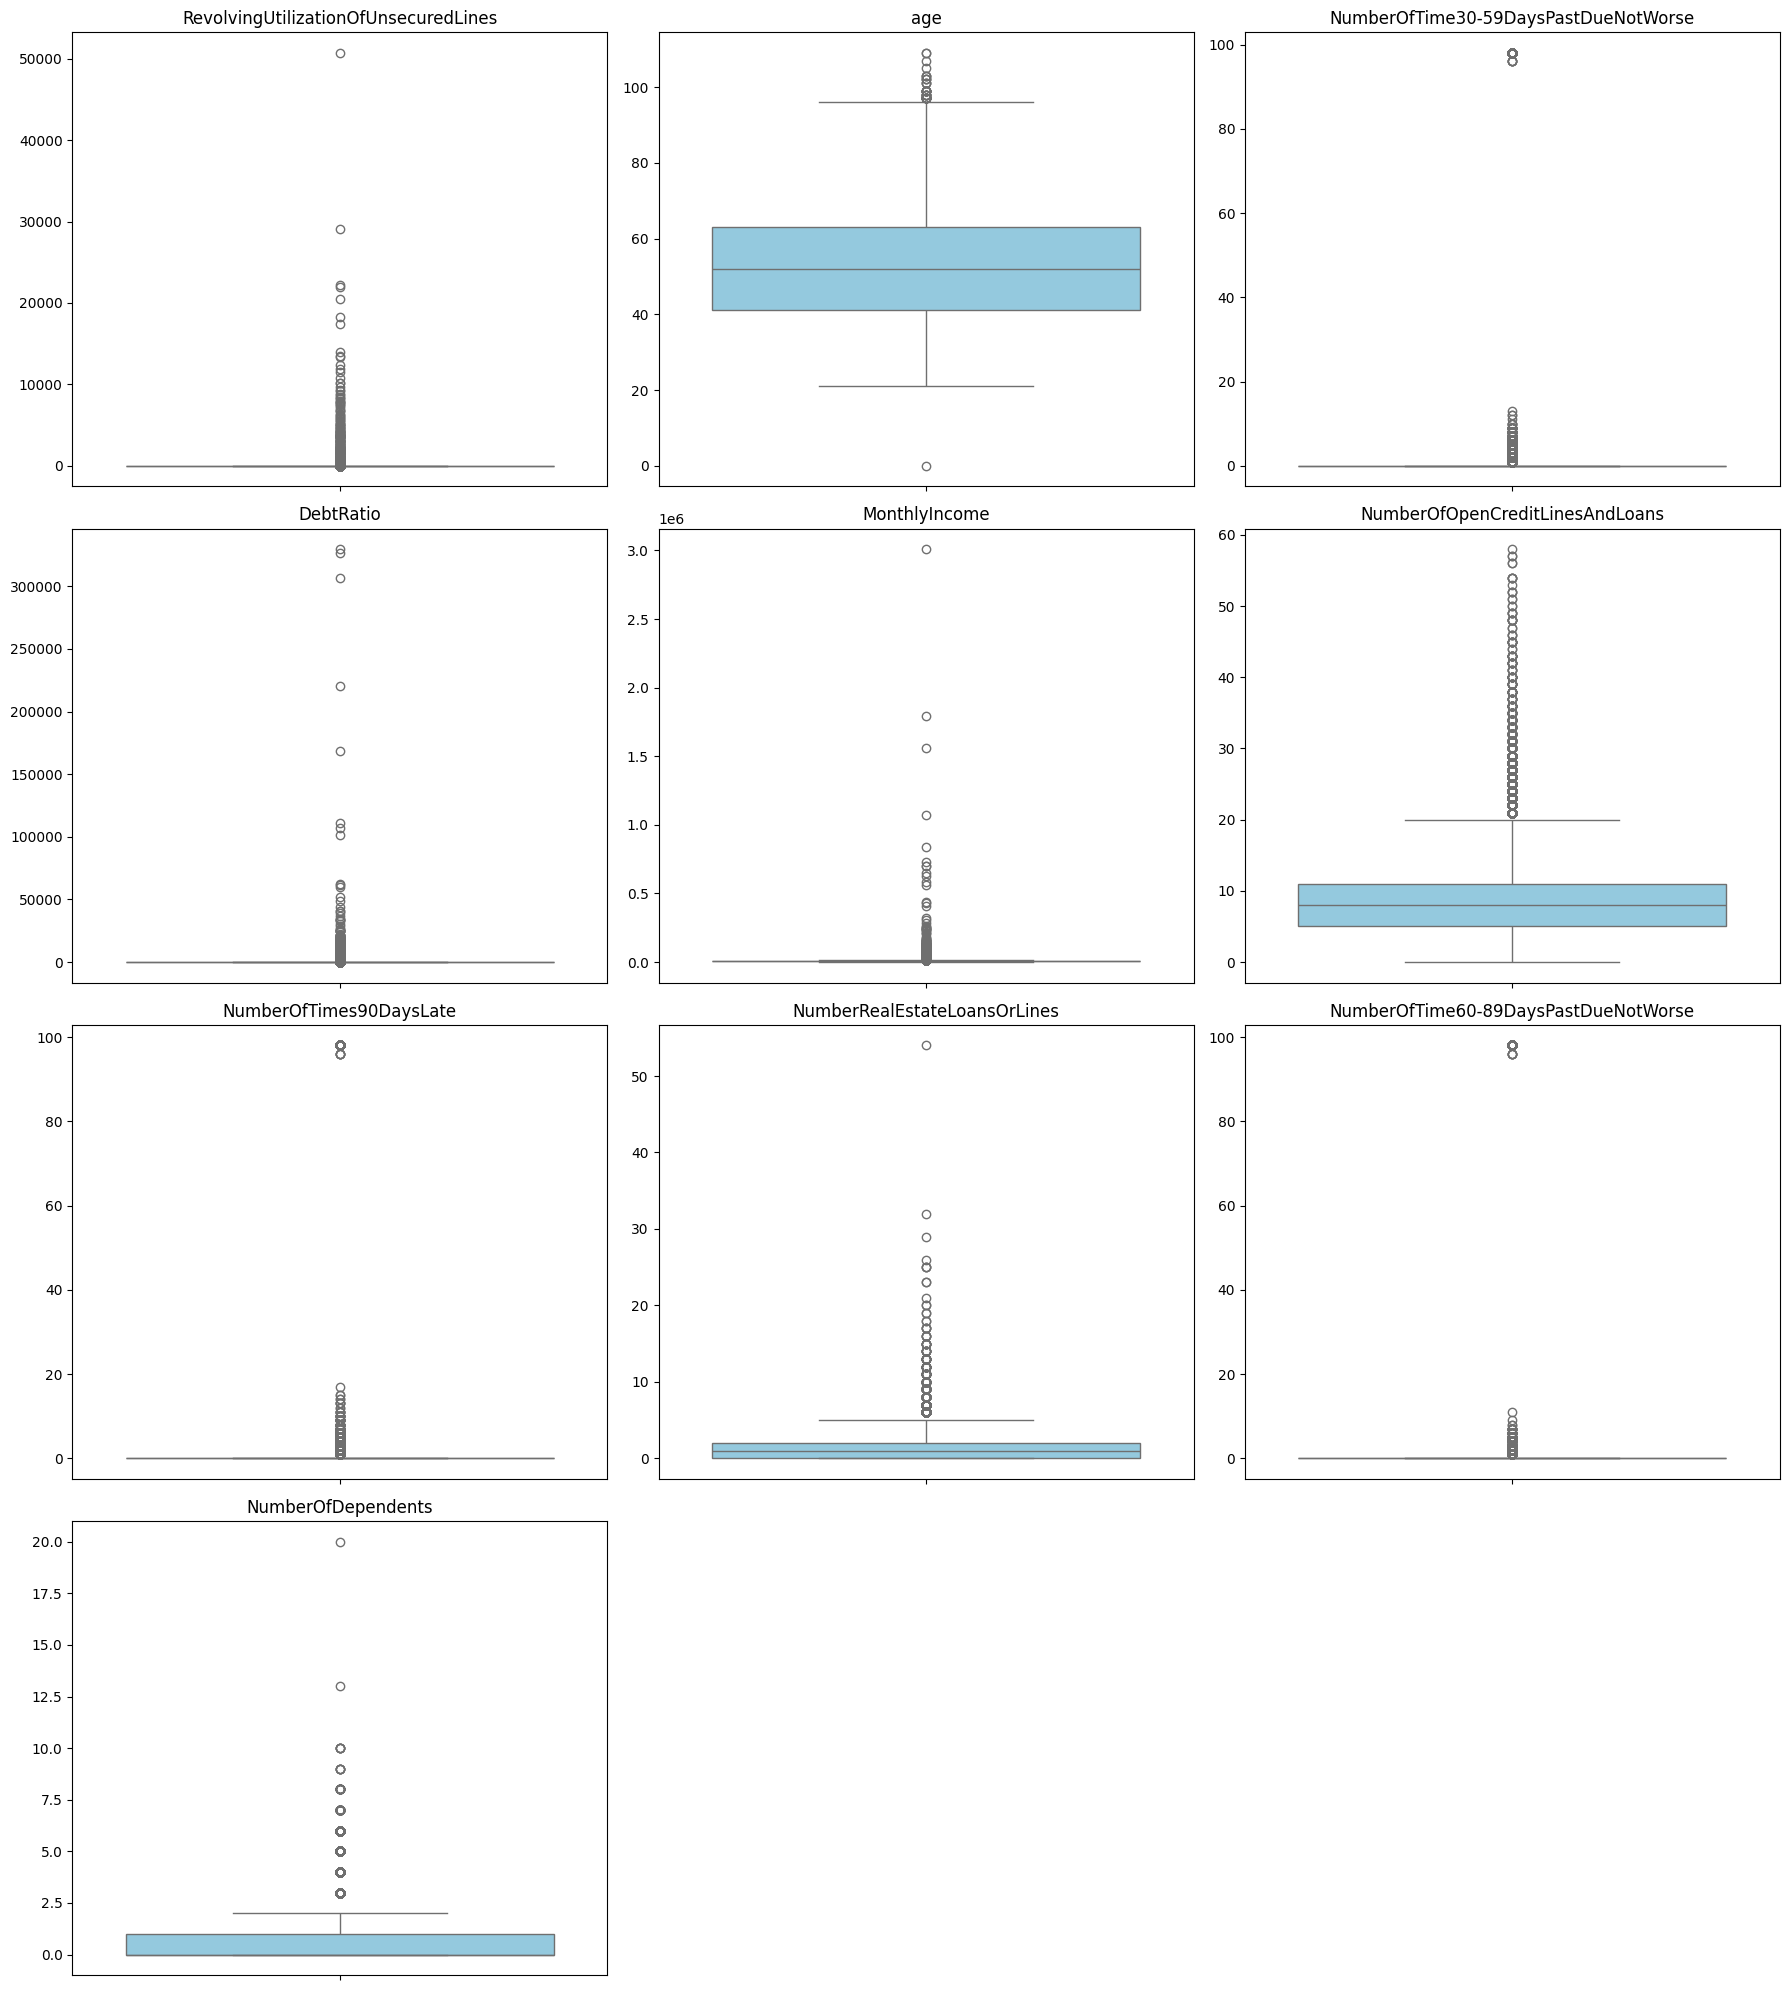

In [12]:
columnas = ['RevolvingUtilizationOfUnsecuredLines', 'age',
       'NumberOfTime30-59DaysPastDueNotWorse', 'DebtRatio', 'MonthlyIncome',
       'NumberOfOpenCreditLinesAndLoans', 'NumberOfTimes90DaysLate',
       'NumberRealEstateLoansOrLines', 'NumberOfTime60-89DaysPastDueNotWorse',
       'NumberOfDependents']
num_columnas = len(columnas)

fig, axes = plt.subplots(nrows=(num_columnas + 2) // 3, ncols=3, figsize=(18, 5 * ((num_columnas + 2) // 3)))
axes = axes.flatten()

for i, col in enumerate(columnas):
    sns.boxplot(y=df[col], ax=axes[i], color='skyblue')
    axes[i].set_title(col)
    axes[i].set_ylabel('')

for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

In [13]:
columnas_morosidad = [
    'NumberOfTime30-59DaysPastDueNotWorse',
    'NumberOfTimes90DaysLate',
    'NumberOfTime60-89DaysPastDueNotWorse'
]

mascara = df[columnas_morosidad].isin([96, 98]).any(axis=1)

display(
    df.loc[mascara, columnas_morosidad]
      .value_counts()
      .reset_index(name='Frecuencia')
)

,NumberOfTime30-59DaysPastDueNotWorse,NumberOfTimes90DaysLate,NumberOfTime60-89DaysPastDueNotWorse,Frecuencia
0,98,98,98,264
1,96,96,96,5


- Se identificó registros con un valor de edad igual a cero y mayores a 100, considerado inconsistente con el contexto del problema. Para conservar la observación sin introducir un valor inválido, se reemplazó por la mediana.
- Los valores 96 y 98 aparecen simultáneamente en las tres variables de morosidad, correspondientes a 269 registros. Esta coincidencia sugiere la posible existencia de una codificación especial, por lo que se procede a imputarlos y crear indicadores binarios que permitan conservar la información de los registros originalmente afectados.

In [14]:
df['age'] = df['age'].apply(lambda x: df['age'].median() if x == 0 or x > 100 else x)

In [15]:
df['NumberOfTime30-59DaysPastDueNotWorseEncoded'] = df['NumberOfTime30-59DaysPastDueNotWorse'].apply(lambda x: 1 if x in [96, 98] else 0)
df['NumberOfTime60-89DaysPastDueNotWorseEncoded'] = df['NumberOfTime60-89DaysPastDueNotWorse'].apply(lambda x: 1 if x in [96, 98] else 0)
df['NumberOfTimes90DaysLateEncoded'] = df['NumberOfTimes90DaysLate'].apply(lambda x: 1 if x in [96, 98] else 0)

df['NumberOfTime30-59DaysPastDueNotWorse'] = df['NumberOfTime30-59DaysPastDueNotWorse'].apply(lambda x: df['NumberOfTime30-59DaysPastDueNotWorse'].median() if x in [96, 98] else x)
df['NumberOfTime60-89DaysPastDueNotWorse'] = df['NumberOfTime60-89DaysPastDueNotWorse'].apply(lambda x: df['NumberOfTime60-89DaysPastDueNotWorse'].median() if x in [96, 98] else x)
df['NumberOfTimes90DaysLate'] = df['NumberOfTimes90DaysLate'].apply(lambda x: df['NumberOfTimes90DaysLate'].median() if x in [96, 98] else x)

A continuación, se analiza la correlación entre las variables del conjunto de datos con el propósito de identificar posibles relaciones lineales y determinar cuáles presentan una mayor asociación con la variable objetivo (SeriousDlqin2yrs).

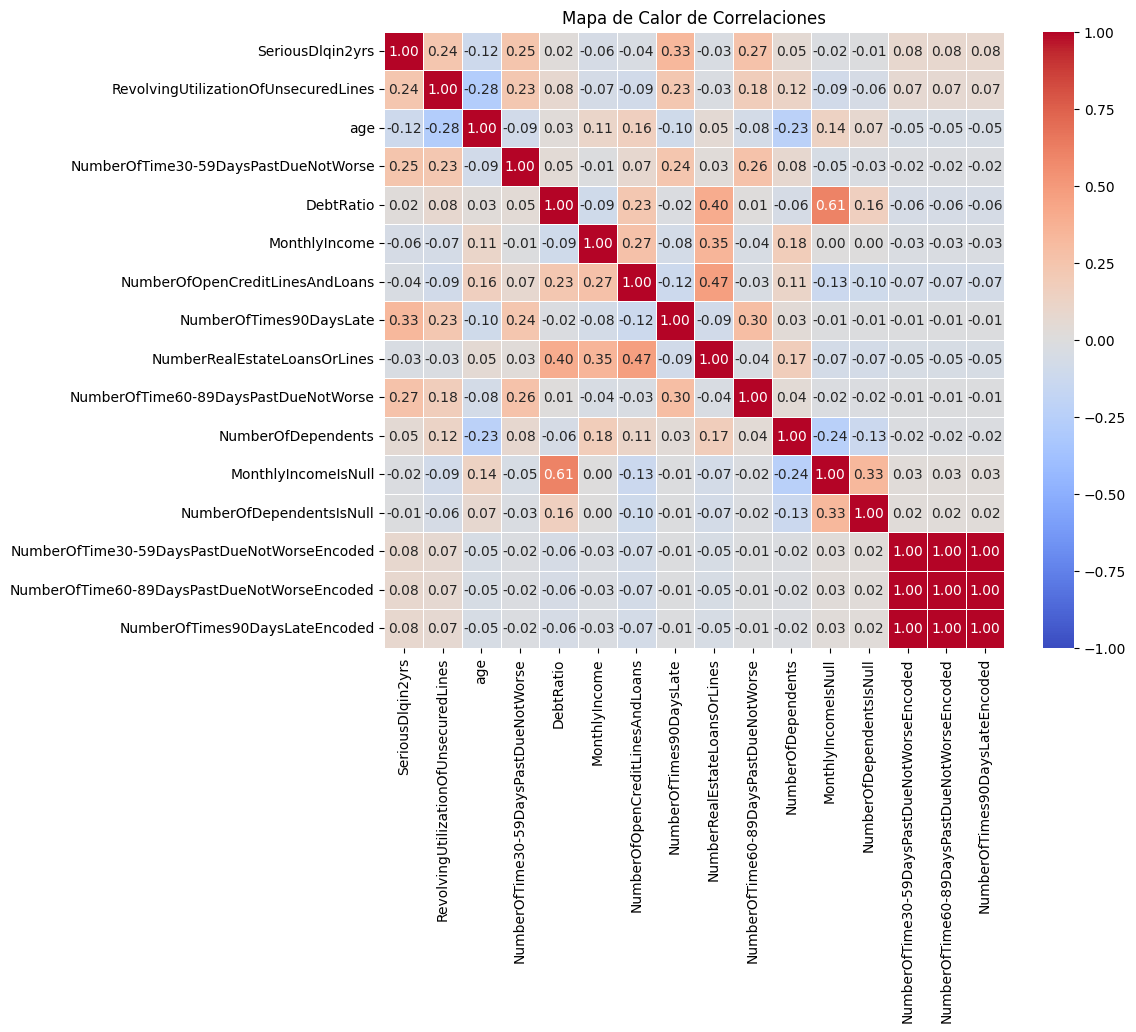

In [16]:
corr_matrix = df.corr(method='spearman')

target_corr = corr_matrix['SeriousDlqin2yrs'].sort_values(ascending=False)

plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap='coolwarm', vmin=-1, vmax=1, linewidths=0.5)
plt.title('Mapa de Calor de Correlaciones')
plt.show()

- Las variables relacionadas con retrasos previos en los pagos presentan las correlaciones positivas más altas con la variable objetivo, lo que sugiere que los antecedentes de incumplimiento constituyen indicadores relevantes para predecir futuros problemas de pago.
- RevolvingUtilizationOfUnsecuredLines también presenta una correlación positiva importante, lo que indica que un mayor nivel de utilización del crédito está asociado con una mayor incidencia de incumplimientos.
- La variable age presenta una correlación negativa con la variable objetivo, sugiriendo que los clientes de mayor edad tienden a presentar una menor incidencia de incumplimiento grave.

## Desarrollo del modelo

Inicialmente, el conjunto de datos se divide en entrenamiento (70%), validación (15%) y prueba (15%), utilizando estratificación para mantener la proporción original de las clases en ambos subconjuntos.

In [17]:
X = df.drop(columns=['SeriousDlqin2yrs'])
y = df['SeriousDlqin2yrs']

In [18]:
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=42, stratify=y_temp
)

En esta etapa se desarrolla el proceso de modelamiento mediante tres algoritmos de clasificación: Random Forest, XGBoost y LightGBM. Posteriormente, se entrenan los modelos considerando el desbalance de clases mediante los parámetros correspondientes de cada algoritmo.

In [19]:
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    class_weight='balanced',
    n_jobs=-1
)

In [20]:
rf_model.fit(X_train, y_train)
rf_val_preds = rf_model.predict_proba(X_val)[:, 1]

In [21]:
neg_pos_ratio = (len(y_train) - sum(y_train)) / sum(y_train)

xgb_model = xgb.XGBClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=5,
    random_state=42,
    scale_pos_weight=neg_pos_ratio,
    n_jobs=-1
)

In [22]:
xgb_model.fit(X_train, y_train)
xgb_val_preds = xgb_model.predict_proba(X_val)[:, 1]

In [23]:
lgb_model = lgb.LGBMClassifier(
    n_estimators=100,
    learning_rate=0.1,
    random_state=42,
    class_weight='balanced',
    n_jobs=-1,
    verbose=-1
)

In [24]:
lgb_model.fit(X_train, y_train)
lgb_val_preds = lgb_model.predict_proba(X_val)[:, 1]

## Evaluación del modelo

Para evaluar el desempeño de los modelos entrenados, se desarrolló una función que calcula las métricas ROC-AUC y Kolmogórov-Smirnov (KS), además del reporte de clasificación. Estas métricas permiten analizar la capacidad de discriminación de los modelos y su desempeño en la identificación de clientes con incumplimiento.

In [25]:
def evaluar_modelo(y_real, y_probabilidades, umbral=0.5):
    # ROC-AUC
    auc = roc_auc_score(y_real, y_probabilidades)
    print(f"ROC-AUC Score: {auc:.4f}")

    # Prueba de Kolmogórov-Smirnov (KS)
    probs_default = y_probabilidades[y_real == 1]
    probs_no_default = y_probabilidades[y_real == 0]

    ks_estadistica, p_value = ks_2samp(probs_default, probs_no_default)
    print(f"Estadística KS: {ks_estadistica * 100:.2f}% (Separación máxima)")

    # Clasificación con un umbral de decisión específico
    y_pred = (y_probabilidades >= umbral).astype(int)
    print("Reporte de Clasificación:")
    print(classification_report(y_real, y_pred, target_names=['No Default (0)', 'Default (1)']))

Resultado de Random Forest.

In [26]:
evaluar_modelo(y_val, rf_val_preds)

ROC-AUC Score: 0.8411
Estadística KS: 53.02% (Separación máxima)
Reporte de Clasificación:
                precision    recall  f1-score   support

No Default (0)       0.94      0.99      0.97     20996
   Default (1)       0.55      0.16      0.25      1504

      accuracy                           0.94     22500
     macro avg       0.75      0.58      0.61     22500
  weighted avg       0.92      0.94      0.92     22500



Resultado de XGBoost.

In [27]:
evaluar_modelo(y_val, xgb_val_preds)

ROC-AUC Score: 0.8697
Estadística KS: 58.73% (Separación máxima)
Reporte de Clasificación:
                precision    recall  f1-score   support

No Default (0)       0.98      0.80      0.88     20996
   Default (1)       0.22      0.79      0.34      1504

      accuracy                           0.80     22500
     macro avg       0.60      0.79      0.61     22500
  weighted avg       0.93      0.80      0.85     22500



Resultado de LightGBM.

In [28]:
evaluar_modelo(y_val, lgb_val_preds)

ROC-AUC Score: 0.8690
Estadística KS: 58.51% (Separación máxima)
Reporte de Clasificación:
                precision    recall  f1-score   support

No Default (0)       0.98      0.81      0.88     20996
   Default (1)       0.22      0.77      0.34      1504

      accuracy                           0.80     22500
     macro avg       0.60      0.79      0.61     22500
  weighted avg       0.93      0.80      0.85     22500



- XGBoost presenta el mejor desempeño en términos de ROC-AUC (0.8697) y KS (58.73%), lo que evidencia una mayor capacidad para diferenciar entre clientes que presentan incumplimiento y aquellos que no.
- En cuanto a la identificación de incumplimientos, Random Forest obtiene una mayor Precision (55%), pero un Recall reducido (16%). En cambio, XGBoost y LightGBM alcanzan mejores valores de Recall (79% y 77%, respectivamente), aunque con una Precision del 22%, lo que implica una mayor cantidad de falsas alarmas.

Dado que el umbral de clasificación predeterminado es 0.5, se busca determinar si existe un umbral que permita maximizar la utilidad financiera de la institución. Para ello, se evalúan diferentes umbrales entre 0.01 y 0.99, calculando la utilidad estimada en función de las ganancias por clientes que cumplen sus obligaciones y las pérdidas asociadas a clientes que incurren en incumplimiento. Finalmente, se identifica el umbral que maximiza dicha utilidad para cada modelo.

In [29]:
def optimizar_umbral_financiero(y_real, y_probabilidades):
    # Definimos los valores financieros por cada escenario
    ganancia_buen_cliente = 1500   # Beneficio por aprobar a alguien que paga (TN)
    perdida_default = -5000        # Pérdida por aprobar a alguien que cae en default (FN)
    costo_oportunidad = -300      # Rechazo a un buen cliente (FP)

    # Probamos umbrales del 1% al 99%
    umbrales = np.linspace(0.01, 0.99, 99)
    resultados = []

    for umbral in umbrales:
        y_pred = (y_probabilidades >= umbral).astype(int)

        tn = np.sum((y_real == 0) & (y_pred == 0)) # Aprobados que pagaron (Ganancia)
        fn = np.sum((y_real == 1) & (y_pred == 0)) # Aprobados que cayeron en default (Pérdida)
        tp = np.sum((y_real == 1) & (y_pred == 1)) # Rechazados que habrían caído en default (Ahorro/Neutral)
        fp = np.sum((y_real == 0) & (y_pred == 1)) # Rechazados que habrían pagado (Costo oportunidad)

        # Cáculo de la utilidad financiera total del umbral
        utilidad_directa = (tn * ganancia_buen_cliente) + (fn * perdida_default)
        costo_oportunidad_total = fp * costo_oportunidad
        utilidad_total = utilidad_directa + costo_oportunidad_total

        resultados.append({
            'umbral': umbral,
            'utilidad_total': utilidad_total,
            'utilidad_directa': utilidad_directa,
            'costo_oportunidad_total': costo_oportunidad_total,
            'aprobados': tn + fn,
            'rechazados': tp + fp
        })

    df_resultados = pd.DataFrame(resultados)

    # Encontramos el umbral que maximiza la utilidad usando la columna correcta
    mejor_fila = df_resultados.loc[df_resultados['utilidad_total'].idxmax()]

    print("Resultado de optimización financiera:")
    print(f"Umbral de decisión óptimo: {mejor_fila['umbral']:.2f}")
    print(f"Utilidad financiera máxima estimada: ${mejor_fila['utilidad_total']:,.2f}")
    print(f"Clientes aprobados: {int(mejor_fila['aprobados'])}")
    print(f"Clientes rechazados: {int(mejor_fila['rechazados'])}")

    return df_resultados

Resultado de Random Forest.

In [30]:
df_simulacion_rf = optimizar_umbral_financiero(y_val, rf_val_preds)

Resultado de optimización financiera:
Umbral de decisión óptimo: 0.28
Utilidad financiera máxima estimada: $25,475,200.00
Clientes aprobados: 21124
Clientes rechazados: 1376


Resultado de XGBoost.

In [31]:
df_simulacion_xgb = optimizar_umbral_financiero(y_val, xgb_val_preds)

Resultado de optimización financiera:
Umbral de decisión óptimo: 0.82
Utilidad financiera máxima estimada: $25,850,600.00
Clientes aprobados: 21019
Clientes rechazados: 1481


Resultado de LightGBM.

In [32]:
df_simulacion_lgb = optimizar_umbral_financiero(y_val, lgb_val_preds)

Resultado de optimización financiera:
Umbral de decisión óptimo: 0.80
Utilidad financiera máxima estimada: $25,859,000.00
Clientes aprobados: 20797
Clientes rechazados: 1703


Los resultados muestran que LightGBM obtiene la mayor utilidad financiera estimada (25,859,000), utilizando un umbral de decisión de 0.80. Le sigue XGBoost con 25,850,600, mientras que Random Forest alcanza 25,475,200. Por lo tanto, se optó por seleccionar el modelo LightGBM.

In [33]:
lgb_test_preds = lgb_model.predict_proba(X_test)[:, 1]

evaluar_modelo(y_test, lgb_test_preds, 0.80)

ROC-AUC Score: 0.8601
Estadística KS: 56.59% (Separación máxima)
Reporte de Clasificación:
                precision    recall  f1-score   support

No Default (0)       0.96      0.95      0.96     20996
   Default (1)       0.42      0.46      0.44      1504

      accuracy                           0.92     22500
     macro avg       0.69      0.71      0.70     22500
  weighted avg       0.92      0.92      0.92     22500



Al incrementar el umbral de decisión a 0.80, el modelo LightGBM mejoró su precisión para identificar clientes que realmente caerían en default (42%), reduciendo los falsos positivos. Sin embargo, esto provocó una disminución del recall al 46%, por lo que aproximadamente la mitad de los clientes morosos no fueron identificados. La optimización financiera seleccionó este umbral porque permitió encontrar un equilibrio entre la detección de clientes morosos y la aprobación de clientes solventes. Como siguiente paso, se lleva a la fase de explicabilidad del modelo mediante SHAP.

In [34]:
explorador_shap_lgb = shap.TreeExplainer(lgb_model)

valores_shap_lgb = explorador_shap_lgb(X_test)

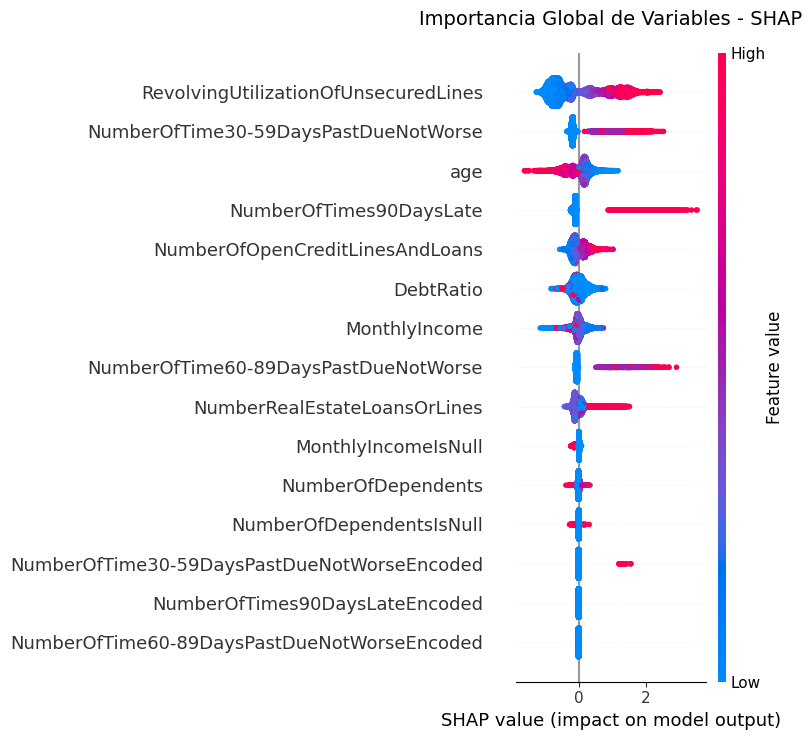

In [35]:
shap.summary_plot(valores_shap_lgb.values, X_test, plot_type="dot", show=False)
plt.title("Importancia Global de Variables - SHAP", fontsize=14, pad=20)
plt.tight_layout()
plt.show()

El análisis de importancia global mediante SHAP permite identificar las variables que tienen mayor influencia en las predicciones del modelo. Entre los principales hallazgos se encuentran:
- Una mayor utilización del crédito tiende a incrementar el riesgo de incumplimiento.
- Los antecedentes de retrasos en los pagos tienen una influencia importante, incrementando el riesgo estimado de incumplimiento.
- La edad presenta una tendencia inversa; los clientes de menor edad tienden a asociarse con un mayor riesgo de incumplimiento, mientras que los de mayor edad muestran una menor propensión.
- Características como DebtRatio, MonthlyIncome y NumberOfDependents presentan una menor influencia  en comparación con la utilización del crédito y el historial de morosidad.

Como siguiente paso, explicamos exactamente por qué el modelo tomó una decisión para un solicitante específico, utilizando un gráfico de cascada.

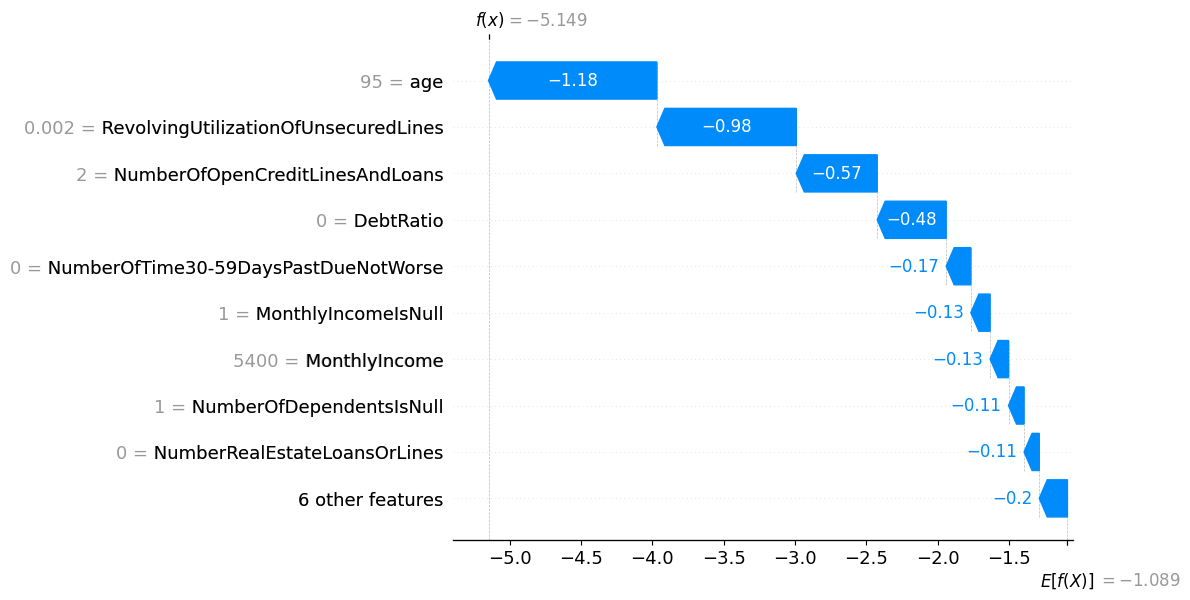

In [37]:
probabilidades_default = xgb_model.predict_proba(X_test)[:, 1]

# Encontrar el índice del cliente con la probabilidad de default más baja
indice_bajo_riesgo = np.argmin(probabilidades_default)

shap.plots.waterfall(valores_shap_lgb[indice_bajo_riesgo])

- El modelo muestra un puntaje muy bajo (-5.149), lo que se traduce en una probabilidad extremadamente baja de impago.
- Su edad (95 años) le resta -1.18 puntos de riesgo.
- Su utilización de crédito es muy baja (0.002), lo que le resta -0.98 puntos al riesgo.
- No registra ningún antecedente de morosidad previa (NumberOfTime30-59DaysPastDue = 0), restando -0.17 puntos.

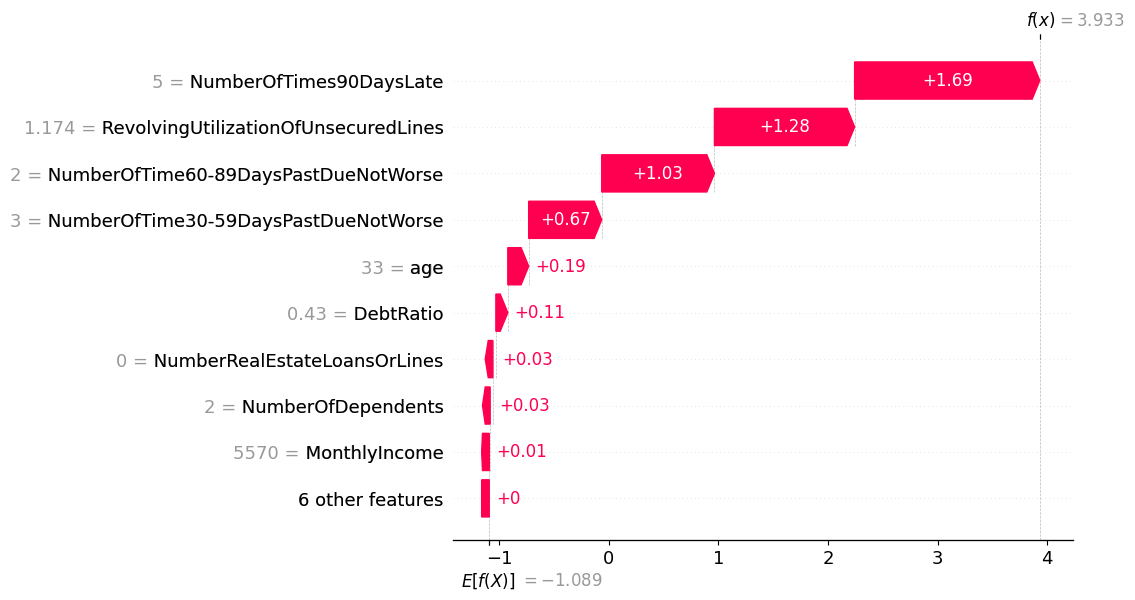

In [38]:
# Encontrar el índice del cliente con la probabilidad de default más alta
indice_alto_riesgo = np.argmax(probabilidades_default)

shap.plots.waterfall(valores_shap_lgb[indice_alto_riesgo])

- Este caso representa lo opuesto al ejemplo anterior, el modelo muestra un puntaje alto (3.933), lo que indica que este solicitante caerá en default.
- El motivo principal de ese puntaje es el historial recurrente de morosidad del cliente, evidenciado por múltiples retrasos graves en sus obligaciones financieras.  
- Su utilización de líneas de crédito es muy alta (1.174), lo que le suma 1.28 puntos al riesgo.

## Conclusiones

- Tras evaluar los tres modelos, XGBoost y LightGBM demostraron una capacidad de discriminación significativamente superior frente a Random Forest.
- El umbral estándar de 0.50 no resulta necesariamente adecuado para la evaluación del riesgo crediticio, debido a que los costos de aprobar a un cliente moroso y rechazar a uno solvente son diferentes. Por ello, se utilizó una función para buscar un equilibrio entre el riesgo asumido y la rentabilidad de la cartera.
- La incorporación de los valores SHAP permitió interpretar las predicciones del modelo e identificar los principales factores asociados al riesgo crediticio. Los resultados muestran que el sobreendeudamiento en líneas revolventes y los antecedentes de morosidad grave son los principales determinantes del riesgo.
- Los gráficos de cascada facilitaron la explicación de las predicciones individuales, permitiendo identificar los factores que contribuyen a la aprobación o rechazo de cada cliente y aportando mayor transparencia y trazabilidad al proceso de evaluación crediticia.